# 00 · Inicio en Google Colab — Proyecto Estadísticas de YouTube

Este notebook prepara el entorno y ejecuta la etapa de datos de principio a fin. Antes de cada celda de código hay una celda de documentación con:

- **Qué hace** la celda.
- **Funciones y parámetros:** cada función que se usa, el valor de cada parámetro y qué significa.
- **Documentación oficial** para profundizar.
- **Para experimentar:** cambios sugeridos para entender el efecto de cada parámetro.

El recorrido detallado por cada etapa del pipeline está en el notebook `01_eda`.

**Antes de ejecutar nada:** *Archivo → Guardar una copia en Drive*. El notebook abierto desde el enlace del taller es de solo lectura; la copia queda en Google Drive y es la que el equipo edita y entrega.

**Secretos necesarios** (panel izquierdo de Colab → *Secretos*; activar *Acceso del notebook* en cada uno):

| Secreto | Para qué | Dónde se obtiene |
| --- | --- | --- |
| `KAGGLE_API_TOKEN` (o `KAGGLE_USERNAME` y `KAGGLE_KEY`) | Descargar el dataset de Kaggle | kaggle.com/settings/api → *Generate New Token* (o *Create Legacy API Key*) |
| `YOUTUBE_API_KEY` | Extraer datos con la YouTube Data API v3 | Google Cloud Console → APIs y servicios → Credenciales |

No se necesita GPU para esta etapa: *Entorno de ejecución → Cambiar tipo de entorno de ejecución* → CPU.

### Celda 1 · Descargar el código del taller

**Qué hace:** descarga el código del taller desde GitHub en `/content/youtube-stats-nlp`, instala las librerías que Colab no trae y permite importar el paquete `ytnlp`. No hay que llenar nada.

| Herramienta | Uso en la celda | Parámetro o valor | Qué significa |
| --- | --- | --- | --- |
| `git clone` | Descarga el repositorio | `--depth 1` | Solo la última versión, sin el historial (más rápido) |
| `git clone` | | `-b main` | Rama que se descarga |
| `git fetch` + `git reset --hard` | Actualiza si ya se descargó en la sesión | `FETCH_HEAD` | Deja el código igual a la última versión publicada |
| `subprocess.run` | Ejecuta comandos del sistema desde Python | `capture_output=True`, `text=True` | Guarda la salida del comando como texto para mostrar errores |
| `pip install` | Instala dependencias | `-q -r requirements-colab.txt` | Modo silencioso; instala la lista del archivo |
| `sys.path.insert` | Hace importable el paquete | `0, ".../src"` | Python busca módulos primero en esa carpeta |

**Documentación oficial**

- git clone: https://git-scm.com/docs/git-clone
- subprocess: https://docs.python.org/3/library/subprocess.html
- pip install: https://pip.pypa.io/en/stable/cli/pip_install/
- sys.path: https://docs.python.org/3/library/sys.html#sys.path

In [1]:
# @title 1 · Descargar el código del taller e instalar dependencias
# Repositorio público del taller (lo define el docente; no se modifica).
REPO_URL = "https://github.com/lemrei2025-ai/Analisis_PLN_Youtube--II.git"
BRANCH = "main"

import os, subprocess, sys

def _git(*args):
    r = subprocess.run(["git", *args], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError("git " + args[0] + " falló:\n" + r.stderr[-500:])

try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    if "USUARIO/REPOSITORIO" in REPO_URL:
        raise ValueError("El repositorio del taller no está configurado; avisar al docente.")
    REPO_DIR = "/content/youtube-stats-nlp"
    if os.path.exists(REPO_DIR):  # actualiza a la última versión publicada
        _git("-C", REPO_DIR, "fetch", "-q", "--depth", "1", "origin", BRANCH)
        _git("-C", REPO_DIR, "reset", "-q", "--hard", "FETCH_HEAD")
    else:
        _git("clone", "-q", "--depth", "1", "-b", BRANCH, REPO_URL, REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    f"{REPO_DIR}/requirements-colab.txt"], check=True)
    os.chdir(REPO_DIR)
else:  # computador local: el notebook se abre desde la carpeta notebooks/
    REPO_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
    os.chdir(REPO_DIR)

sys.path.insert(0, os.path.join(REPO_DIR, "src"))
print("Código del taller listo en", REPO_DIR)

Código del taller listo en /content/youtube-stats-nlp


### Celda 2 · Montar Google Drive y cargar los secretos

**Qué hace:** conecta Google Drive (donde se guardan datos, reportes y configuración), lee las credenciales de los Secretos de Colab y muestra un resumen del entorno.

| Función | Parámetro | Valor usado | Qué significa |
| --- | --- | --- | --- |
| `google.colab.drive.mount` | `mountpoint` | `"/content/drive"` | Carpeta donde aparece Drive dentro de Colab |
| `google.colab.userdata.get` | nombre del secreto | `KAGGLE_API_TOKEN`, `YOUTUBE_API_KEY`, ... | Lee el valor guardado en el panel *Secretos*; se copia a `os.environ` |
| `os.environ` | `YTNLP_STORAGE` | ruta de `CARPETA_DRIVE` | Variable de entorno que indica al código dónde guardar resultados |
| `logging.basicConfig` | `level` | `logging.INFO` | Muestra los mensajes `INFO` y `WARNING` del pipeline |
| | `format` | `"%(levelname)s %(message)s"` | Formato de cada mensaje |
| | `force` | `True` | Reemplaza la configuración de registro que trae Colab |

**Parámetro del formulario:** `CARPETA_DRIVE` es la ruta, dentro de Drive, donde se guarda todo el trabajo del equipo. Si la carpeta compartida tiene otro nombre, se cambia aquí.

**Documentación oficial**

- Archivos y Google Drive en Colab: https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/io.ipynb
- os.environ: https://docs.python.org/3/library/os.html#os.environ
- logging.basicConfig: https://docs.python.org/3/library/logging.html#logging.basicConfig

In [2]:
# @title 2 · Montar Drive y cargar secretos
CARPETA_DRIVE = "MyDrive/UDEC EN GRUPO/2026/Procesamiento Lenguaje Natural/Taller 15 de Octubre/YT2"  # @param {type:"string"}

import logging
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s", force=True)

from ytnlp.colab import setup
info = setup(drive_folder=CARPETA_DRIVE)

Mounted at /content/drive


INFO NumExpr defaulting to 2 threads.


Entorno
  entorno           Google Colab
  python            3.13.16
  pandas            2.2.3
  numpy             2.4.6
  scikit-learn      1.6.1
  gpu               GPU 0: Tesla T4 (UUID: GPU-214a05ca-ffa8-d928-728c-967755232780)
  repo              /content/youtube-stats-nlp
  datos y reportes  /content/drive/MyDrive/UDEC EN GRUPO/2026/Procesamiento Lenguaje Natural/Taller 15 de Octubre/YT2
Configuración
  origen            config_equipo.yaml
  target            engagement
  comentarios/video 200
Secretos
  KAGGLE_API_TOKEN  OK
  KAGGLE_USERNAME   OK
  KAGGLE_KEY        OK
  YOUTUBE_API_KEY   OK


## 3 · Verificar que todo funciona

**Qué hace:** ejecuta las pruebas automáticas y el pipeline completo sobre una muestra **sintética** incluida en el taller. No requiere credenciales; sus resultados no sirven para conclusiones.

**El pipeline** (`ytnlp.pipeline.run`) ejecuta seis etapas, siempre en el mismo orden. El notebook `01_eda` las recorre una a una.

| Etapa | Librería principal | Funciones y parámetros clave |
| --- | --- | --- |
| 1. Ingesta | pandas, kagglehub, requests | `pd.read_csv`, `kagglehub.dataset_download`, YouTube Data API |
| 2. Validación | pandera | `DataFrameSchema`, `Column(nullable, coerce)`, `Check.ge(0)`, `validate(lazy=True)` |
| 3. Limpieza | emoji, re, unicodedata | `emoji.demojize`, expresiones regulares, `unicodedata.normalize("NFKC")` |
| 4. Features | pandas, numpy | `groupby`, `np.average(weights=...)`, `np.log1p`, `pd.cut` |
| 5. Análisis | scipy, numpy, scikit-learn | `spearmanr`, `kruskal`, `wilcoxon`, `np.polyfit`, `mutual_info_classif` |
| 6. Modelos de referencia | scikit-learn | `TfidfVectorizer`, `Ridge`, `LogisticRegression`, `train_test_split` |

| Función | Parámetro | Valor usado | Qué significa |
| --- | --- | --- | --- |
| `pytest` (línea de comandos) | `-q` | | Salida resumida: una línea con el número de pruebas que pasan |
| | `-p no:cacheprovider` | | No crea la carpeta de caché de pytest |
| `run` (pipeline del taller) | `source` | `"sample"` | Fuente de datos: `sample`, `kaggle` o `api` |
| | `skip_model` | `False` (por defecto) | Si es `True`, omite la etapa 6 |

**Documentación oficial**

- pytest: https://docs.pytest.org/en/stable/getting-started.html

In [3]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider"], check=False)
subprocess.run([sys.executable, "scripts/make_sample_data.py"], check=True)

from ytnlp.pipeline import run
run("sample")

INFO 1/6 Ingesta (sample)
INFO 2/6 Validación
INFO    filas descartadas: videos=0 comentarios=1
INFO 3/6 Limpieza
INFO 4/6 Features
INFO    300 videos x 28 columnas
INFO 5/6 Análisis estadísticos
INFO 6/6 Baselines y curva de aprendizaje
INFO Listo. Reportes en /content/drive/MyDrive/UDEC EN GRUPO/2026/Procesamiento Lenguaje Natural/Taller 15 de Octubre/YT2/reports


{'videos': 300,
 'comentarios': 2492,
 'features': (300, 28),
 'baseline': {'dummy': {'MAE': 0.5008, 'R2': -0.0248, 'spearman': 0.0},
  'contexto (sin texto)': {'MAE': 0.4821, 'R2': -0.0412, 'spearman': 0.2703},
  'contexto + features de comentarios': {'MAE': 0.4127,
   'R2': 0.0966,
   'spearman': 0.5791},
  'contexto + features + TF-IDF': {'MAE': 0.4594,
   'R2': 0.0285,
   'spearman': 0.4111}}}

## 4 · Configuración del equipo

**Qué hace:** guarda en Drive (`config_equipo.yaml`) las decisiones del equipo. Esos valores se combinan con la configuración base del taller (`configs/config.yaml`) en todas las sesiones y notebooks. El código del taller no se modifica.

**Parámetros del formulario**

| Parámetro | Valor por defecto | Qué significa | Opciones |
| --- | --- | --- | --- |
| `TARGET` | `engagement` | Variable que se va a predecir | `engagement`: log((likes + comentarios) / vistas) · `log_views`: log(1 + vistas) · `log_likes`: log(1 + likes) · `perf_class`: clase bajo / medio / alto según el engagement |
| `COMENTARIOS_POR_VIDEO` | `100` | Máximo de comentarios por video al extraer con la API (sección 7) | Entero positivo; cada 100 comentarios cuestan 1 unidad de cuota |
| `RESTABLECER` | `False` | Borra los cambios del equipo y vuelve a la configuración base | `True` / `False` |

**Todos los parámetros de la configuración base** (`configs/config.yaml`). Cualquiera se puede cambiar con `config.set_overrides(...)`, usando doble guion bajo para los niveles; por ejemplo `config.set_overrides(stats__alpha=0.01)`.

| Parámetro | Valor | Qué controla |
| --- | --- | --- |
| `kaggle.dataset` | `advaypatil/youtube-statistics` | Identificador del dataset en Kaggle |
| `api.max_comments_per_video` | `100` | Comentarios máximos por video en la extracción |
| `api.order` | `relevance` | Orden de los comentarios que devuelve la API: `relevance` (más relevantes) o `time` (más recientes) |
| `api.batch_size` | `50` | IDs de video por cada llamada a `videos.list` |
| `api.daily_quota` | `10000` | Unidades de cuota diarias; el extractor se detiene antes de superarlas |
| `cleaning.min_comment_tokens` | `1` | Comentarios con menos palabras se descartan |
| `cleaning.drop_duplicate_comments` | `true` | Elimina comentarios repetidos dentro del mismo video (spam) |
| `cleaning.demojize` | `true` | Convierte emojis en texto (por ejemplo `:fire:`) en lugar de borrarlos |
| `target` | `engagement` | Variable objetivo (ver tabla anterior) |
| `perf_class_quantiles` | `[0.33, 0.66]` | Cuantiles de engagement que separan las clases bajo, medio y alto |
| `min_views_for_engagement` | `100` | Videos con menos vistas no tienen engagement (el cociente sería inestable) |
| `model.test_size` | `0.2` | Proporción de videos reservada para evaluar los modelos |
| `model.random_state` | `42` | Semilla aleatoria: con el mismo valor, la división es siempre la misma |
| `model.learning_curve_fractions` | `[0.1, 0.25, 0.5, 0.75, 1.0]` | Porcentajes del entrenamiento usados en la curva de aprendizaje |
| `stats.bootstrap_iterations` | `2000` | Remuestreos para los intervalos de confianza por bootstrap |
| `stats.alpha` | `0.05` | Nivel de significancia de las pruebas estadísticas |
| `stats.top_k_words` | `20` | Palabras distintivas que se muestran por grupo |

| Función | Parámetro | Qué significa |
| --- | --- | --- |
| `yaml.safe_load` | archivo YAML | Lee la configuración solo con tipos básicos de Python (seguro ante archivos no confiables) |
| `yaml.safe_dump` | `allow_unicode=True`, `sort_keys=False` | Escribe tildes tal cual y conserva el orden de las claves |

**Documentación oficial**

- Formato YAML y PyYAML: https://pyyaml.org/wiki/PyYAMLDocumentation

**Para experimentar:** cambiar `TARGET` a `perf_class`, ejecutar esta celda y luego la sección 5. En `baseline_report.md` las métricas cambian de regresión (MAE, R²) a clasificación (accuracy, F1).

In [4]:
# @title Guardar configuración del equipo
TARGET = "engagement"  # @param ["engagement", "log_views", "log_likes", "perf_class"]
COMENTARIOS_POR_VIDEO = 200  # @param {type:"integer"}
RESTABLECER = False  # @param {type:"boolean"}

from ytnlp import config
if RESTABLECER:
    config.reset_overrides()
    print("Configuración base del taller restablecida.")
else:
    destino = config.set_overrides(target=TARGET, api__max_comments_per_video=COMENTARIOS_POR_VIDEO)
    print("Configuración guardada en", destino)
cfg = config.load_config()
print("target =", cfg["target"], "| comentarios por video =", cfg["api"]["max_comments_per_video"])

Configuración guardada en /content/drive/MyDrive/UDEC EN GRUPO/2026/Procesamiento Lenguaje Natural/Taller 15 de Octubre/YT2/config_equipo.yaml
target = engagement | comentarios por video = 200


## 5 · Datos reales de Kaggle

**Qué hace:** descarga el dataset de Kaggle a Drive (solo la primera vez) y ejecuta el pipeline completo con datos reales. Requiere el secreto `KAGGLE_API_TOKEN` (o el par heredado `KAGGLE_USERNAME` y `KAGGLE_KEY`).

| Función | Parámetro | Valor usado | Qué significa |
| --- | --- | --- | --- |
| `kagglehub.dataset_download` | `handle` | `"advaypatil/youtube-statistics"` | Dataset en formato `usuario/nombre`; se descarga la versión más reciente a una caché local |
| `pd.read_csv` | ruta del archivo | `videos-stats.csv`, `comments.csv` | Lee cada CSV como un DataFrame |
| `pd.to_datetime` | `errors` | `"coerce"` | Las fechas inválidas se convierten en `NaT` (nulo) en lugar de producir un error |
| | `utc` | `True` | Todas las fechas quedan en la zona horaria UTC |
| `pd.to_numeric` | `errors` | `"coerce"` | Los valores no numéricos se convierten en `NaN` |
| `DataFrame.to_parquet` | `index` | `False` | Guarda los datos limpios en formato Parquet, sin la columna de índice |

**Archivos del dataset**

- `videos-stats.csv`: título, Video ID, fecha de publicación, keyword (tema de búsqueda), likes, comentarios y vistas.
- `comments.csv`: Video ID, texto del comentario, likes del comentario y sentimiento (0 negativo, 1 neutral, 2 positivo).

**Documentación oficial**

- kagglehub: https://github.com/Kaggle/kagglehub
- Dataset en Kaggle: https://www.kaggle.com/datasets/advaypatil/youtube-statistics
- pandas.read_csv: https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
- pandas.to_datetime: https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html
- pandas.to_numeric: https://pandas.pydata.org/docs/reference/api/pandas.to_numeric.html
- pandas.DataFrame.to_parquet: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_parquet.html

In [5]:
from ytnlp.data.kaggle_source import has_credentials
from ytnlp.pipeline import run
if not has_credentials():
    print("Faltan los secretos de Kaggle; ver la tabla al inicio del notebook.")
else:
    print(run("kaggle"))

INFO 1/6 Ingesta (kaggle)
INFO Dataset de Kaggle ya presente en /content/drive/MyDrive/UDEC EN GRUPO/2026/Procesamiento Lenguaje Natural/Taller 15 de Octubre/YT2/data/raw/kaggle
INFO 2/6 Validación
INFO    filas descartadas: videos=9 comentarios=0
INFO 3/6 Limpieza
INFO 4/6 Features
INFO    1861 videos x 28 columnas
INFO 5/6 Análisis estadísticos
INFO 6/6 Baselines y curva de aprendizaje
INFO Listo. Reportes en /content/drive/MyDrive/UDEC EN GRUPO/2026/Procesamiento Lenguaje Natural/Taller 15 de Octubre/YT2/reports


{'videos': 1861, 'comentarios': 18153, 'features': (1861, 28), 'baseline': {'dummy': {'MAE': 0.6121, 'R2': -0.0003, 'spearman': 0.0}, 'contexto (sin texto)': {'MAE': 0.4346, 'R2': 0.4859, 'spearman': 0.6824}, 'contexto + features de comentarios': {'MAE': 0.4383, 'R2': 0.4765, 'spearman': 0.6748}, 'contexto + features + TF-IDF': {'MAE': 0.4151, 'R2': 0.5227, 'spearman': 0.7106}}}


## 6 · Ver los reportes

**Qué hace:** muestra en el notebook el reporte elegido en el formulario. Los mismos archivos están en Drive, en `ytnlp-proyecto/reports/`.

| Reporte | Contenido |
| --- | --- |
| `quality_report.md` | Reglas violadas, nulos, duplicados, inconsistencias, ruido de texto, balance, representatividad y métricas de monitoreo |
| `stats_report.md` | Nueve análisis estadísticos con pregunta, prueba, resultado y conclusión, más las figuras |
| `baseline_report.md` | Modelos de referencia con y sin comentarios y curva de aprendizaje |

| Función | Parámetro | Qué significa |
| --- | --- | --- |
| `IPython.display.Markdown` | texto | Muestra el texto con formato (títulos, tablas) |
| `IPython.display.Image` | `filename`, `width` | Muestra una imagen del disco con el ancho indicado en píxeles |

**Documentación oficial**

- IPython.display: https://ipython.readthedocs.io/en/stable/api/generated/IPython.display.html

# Análisis estadísticos no triviales

## 1 cola pesada views

**Pregunta:** ¿Las vistas siguen una distribución de cola pesada? ¿Log-normal o ley de potencias?

**Prueba:** MLE de Pareto y log-normal en la cola (x ≥ mediana) + prueba de Vuong

**Resultado:**

```json
{
  "alpha_pareto": 1.526,
  "LR_lognormal_vs_pareto": -63.34,
  "vuong_z": -2.874,
  "p_valor": 0.004,
  "pct_vistas_en_top10pct": 88.6
}
```

**Conclusión:** El 10 % de videos con más vistas concentra 88.6 % de las vistas. El ajuste favorece ley de potencias (p=0.00405). Implicación: modelar log(views) o métricas relativas, no views crudas.

## 2 sentimiento vs engagement

**Pregunta:** ¿sent_mean se asocia con target_engagement?

**Prueba:** Spearman y Kendall, IC 95 % por bootstrap (2000 réplicas)

**Resultado:**

```json
{
  "n": 1857,
  "spearman_rho": -0.0075,
  "IC95": [
    -0.0529,
    0.0392
  ],
  "p_valor": 0.7474,
  "kendall_tau": -0.0051,
  "p_kendall": 0.7509
}
```

**Conclusión:** ρ=-0.007 [-0.053, 0.039]; el IC incluye 0.

## 3 polarizacion vs engagement

**Pregunta:** ¿polarization se asocia con target_engagement?

**Prueba:** Spearman y Kendall, IC 95 % por bootstrap (2000 réplicas)

**Resultado:**

```json
{
  "n": 1857,
  "spearman_rho": -0.0076,
  "IC95": [
    -0.0499,
    0.0358
  ],
  "p_valor": 0.7422,
  "kendall_tau": -0.005,
  "p_kendall": 0.754
}
```

**Conclusión:** ρ=-0.008 [-0.050, 0.036]; el IC incluye 0.

## 4 engagement por keyword

**Pregunta:** ¿target_engagement difiere entre valores de keyword?

**Prueba:** Kruskal-Wallis + post-hoc de Dunn (Bonferroni); efecto ε²

**Resultado:**

```json
{
  "H": 669.257,
  "p_valor": 0.0,
  "epsilon2": 0.3465,
  "grupos": 41,
  "mediana_por_grupo_top5": {
    "crypto": 0.08475,
    "reaction": 0.06489,
    "asmr": 0.05084,
    "nintendo": 0.05044,
    "trolling": 0.04826
  },
  "pares_significativos": 258,
  "ejemplos_pares": [
    {
      "a": "animals",
      "b": "apple",
      "z": -6.232,
      "p_bonferroni": 0.0
    },
    {
      "a": "animals",
      "b": "asmr",
      "z": -9.552,
      "p_bonferroni": 0.0
    },
    {
      "a": "animals",
      "b": "biology",
      "z": -4.24,
      "p_bonferroni": 0.0184
    },
    {
      "a": "animals",
      "b": "business",
      "z": -5.47,
      "p_bonferroni": 0.0
    },
    {
      "a": "animals",
      "b": "chess",
      "z": -6.046,
      "p_bonferroni": 0.0
    }
  ]
}
```

**Conclusión:** ε²=0.347 (grande); 258 de 820 pares difieren tras Bonferroni. Si el efecto es relevante, controlar por keyword en el modelo.

## 5 regresion con controles

**Pregunta:** ¿Las features de comentarios explican log_engagement una vez se controla por keyword y edad?

**Prueba:** OLS con efectos fijos por keyword, coeficientes estandarizados, errores robustos HC1

**Resultado:**

```json
{
  "n": 1857,
  "R2": 0.477,
  "coeficientes": {
    "sent_mean": {
      "beta_std": 0.003,
      "se_HC1": 0.0262,
      "p_valor": 0.9083
    },
    "polarization": {
      "beta_std": 0.0007,
      "se_HC1": 0.0236,
      "p_valor": 0.9777
    },
    "tokens_mean": {
      "beta_std": 0.0146,
      "se_HC1": 0.028,
      "p_valor": 0.6034
    },
    "ttr": {
      "beta_std": -0.0792,
      "se_HC1": 0.0333,
      "p_valor": 0.0174
    },
    "log_age_days": {
      "beta_std": -0.3709,
      "se_HC1": 0.0204,
      "p_valor": 0.0
    }
  }
}
```

**Conclusión:** R²=0.477. Significativas al 5 %: ttr, log_age_days. Es asociación, no causalidad.

## 6 zipf heaps

**Pregunta:** ¿El vocabulario de los comentarios se comporta como lenguaje natural o hay mucho ruido?

**Prueba:** Ajuste log-log de Zipf (frecuencia vs rango) y de Heaps (V = K·N^β)

**Resultado:**

```json
{
  "tokens": 612914,
  "vocabulario": 63696,
  "pendiente_zipf": -1.193,
  "beta_heaps": 0.712,
  "pct_hapax": 62.5
}
```

**Conclusión:** Pendiente de Zipf -1.19 (≈ -1 en lenguaje natural) y β de Heaps 0.71 (típico 0,4–0,6). β alto o muchos hapax indican ruido (typos, spam, varios idiomas) y justifican normalización o subword tokenization.

## 7 palabras distintivas

**Pregunta:** ¿Qué palabras distinguen los comentarios de videos de desempeño alto vs bajo?

**Prueba:** Log-odds ratio ponderado con prior de Dirichlet informativo (z > 1,96 ≈ p < 0,05)

**Resultado:**

```json
{
  "top_alto": [
    {
      "palabra": "game",
      "z": 5.64
    },
    {
      "palabra": "btc",
      "z": 4.89
    },
    {
      "palabra": "crypto",
      "z": 4.73
    },
    {
      "palabra": "data",
      "z": 4.27
    },
    {
      "palabra": "o",
      "z": 4.19
    },
    {
      "palabra": "sat",
      "z": 3.66
    },
    {
      "palabra": "content",
      "z": 3.62
    },
    {
      "palabra": "trade",
      "z": 3.33
    },
    {
      "palabra": "je",
      "z": 3.28
    },
    {
      "palabra": "release]",
      "z": 3.04
    },
    {
      "palabra": "marvel",
      "z": 3.02
    },
    {
      "palabra": "splatoon",
      "z": 2.98
    },
    {
      "palabra": "as",
      "z": 2.97
    },
    {
      "palabra": "market",
      "z": 2.92
    },
    {
      "palabra": "pour",
      "z": 2.9
    },
    {
      "palabra": "science",
      "z": 2.89
    },
    {
      "palabra": "[ncs",
      "z": 2.86
    },
    {
      "palabra": "hrithik",
      "z": 2.81
    },
    {
      "palabra": "trading",
      "z": 2.81
    },
    {
      "palabra": "à",
      "z": 2.8
    }
  ],
  "top_bajo": [
    {
      "palabra": "-",
      "z": -10.45
    },
    {
      "palabra": "song",
      "z": -7.41
    },
    {
      "palabra": "22:22",
      "z": -6.18
    },
    {
      "palabra": "son",
      "z": -5.94
    },
    {
      "palabra": "hermosa",
      "z": -5.67
    },
    {
      "palabra": "mejores",
      "z": -5.63
    },
    {
      "palabra": "tan",
      "z": -5.63
    },
    {
      "palabra": "3x3",
      "z": -5.61
    },
    {
      "palabra": "23:23",
      "z": -5.59
    },
    {
      "palabra": "se",
      "z": -5.59
    },
    {
      "palabra": "ft.",
      "z": -5.53
    },
    {
      "palabra": "los",
      "z": -5.37
    },
    {
      "palabra": "unos",
      "z": -4.99
    },
    {
      "palabra": "conciertos",
      "z": -4.96
    },
    {
      "palabra": "cube",
      "z": -4.76
    },
    {
      "palabra": "wanna",
      "z": -4.61
    },
    {
      "palabra": "elecciones",
      "z": -4.52
    },
    {
      "palabra": "culturales",
      "z": -4.52
    },
    {
      "palabra": "hopi:",
      "z": -4.32
    },
    {
      "palabra": "joonie:",
      "z": -4.27
    }
  ],
  "palabras_significativas": 315
}
```

**Conclusión:** Insumo para features léxicas e interpretabilidad del modelo.

## 8 comentario top vs promedio

**Pregunta:** ¿El comentario con más likes es más positivo o negativo que el promedio?

**Prueba:** Wilcoxon de rangos con signo (pareado por video); efecto r rango-biserial

**Resultado:**

```json
{
  "n": 1861,
  "diferencia_mediana": 0.0,
  "W": 742871.0,
  "p_valor": 0.0,
  "r_rango_biserial": 0.1425
}
```

**Conclusión:** Si difiere, la audiencia premia con likes un tono distinto al promedio: usar el sentimiento ponderado por likes como feature.

## 9 informacion mutua

**Pregunta:** ¿Cuánta información aporta cada feature de comentarios sobre target_perf_class?

**Prueba:** Información mutua (k-NN) + prueba de permutación (200 réplicas)

**Resultado:**

```json
{
  "n": 1857,
  "ranking": [
    {
      "feature": "sent_weighted",
      "MI": 0.027,
      "p_perm": 0.035
    },
    {
      "feature": "emoji_per_comment",
      "MI": 0.023,
      "p_perm": 0.04
    },
    {
      "feature": "sent_mean",
      "MI": 0.0201,
      "p_perm": 0.08
    },
    {
      "feature": "pct_question",
      "MI": 0.0185,
      "p_perm": 0.08
    },
    {
      "feature": "sent_std",
      "MI": 0.0182,
      "p_perm": 0.1
    },
    {
      "feature": "pct_neg",
      "MI": 0.0174,
      "p_perm": 0.09
    },
    {
      "feature": "ttr",
      "MI": 0.0137,
      "p_perm": 0.129
    },
    {
      "feature": "polarization",
      "MI": 0.0115,
      "p_perm": 0.214
    },
    {
      "feature": "pct_pos",
      "MI": 0.0013,
      "p_perm": 0.378
    },
    {
      "feature": "tokens_mean",
      "MI": 0.0,
      "p_perm": 1.0
    },
    {
      "feature": "pct_exclaim",
      "MI": 0.0,
      "p_perm": 1.0
    }
  ]
}
```

**Conclusión:** Features con p_perm < 0,05 aportan información más allá del azar.



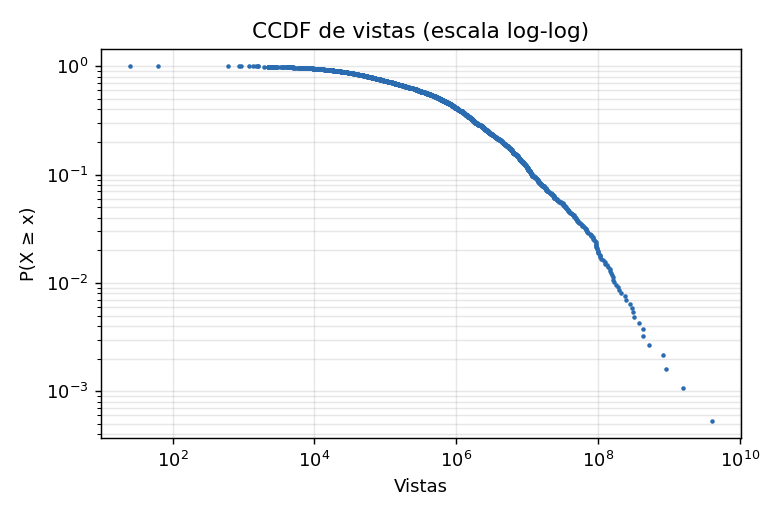

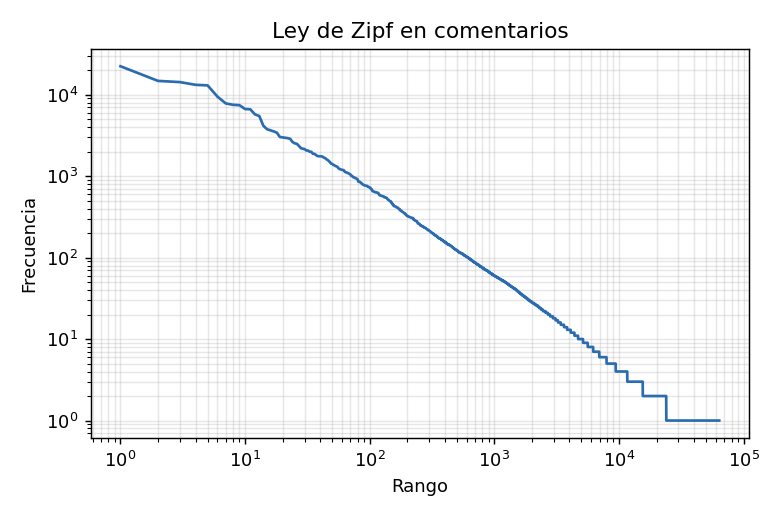

In [6]:
# @title Mostrar reportes
REPORTE = "stats_report.md"  # @param ["quality_report.md", "stats_report.md", "baseline_report.md"]
from IPython.display import Image, Markdown, display
from ytnlp.config import path

rep = path("reports")
texto = (rep / REPORTE).read_text(encoding="utf-8")
display(Markdown(texto.split("## Figuras")[0]))
if REPORTE == "stats_report.md":
    for img in sorted((rep / "figures").glob("*.png")):
        display(Image(filename=str(img), width=520))

## 7 · Ampliar los datos con la YouTube Data API

**Qué hace:** elige videos del dataset de Kaggle repartidos entre todas las keywords (para poder comparar temas) y descarga, por video, estadísticas actualizadas, duración, suscriptores del canal y comentarios. La extracción queda en Drive en `data/raw/api/<fecha>/` y luego se ejecuta el pipeline con esos datos. Ejecutar esta sección en días distintos genera una serie de tiempo y alimenta el historial de monitoreo (`reports/monitoring_history.csv`).

**Parámetro del formulario:** `LIMITE_VIDEOS` (por defecto 50) es la cantidad de videos que se extraen. Con menos de 30 videos no se entrenan los modelos de referencia.

**Métodos de la API**

| Método | Parámetro | Valor usado | Qué significa |
| --- | --- | --- | --- |
| `videos.list` | `part` | `snippet,statistics,contentDetails` | Título, fecha, canal, categoría y tags; vistas, likes y comentarios; duración |
| | `id` | hasta 50 IDs separados por coma | Videos consultados en una sola llamada (1 unidad de cuota) |
| `channels.list` | `part` | `statistics` | Suscriptores y número de videos del canal |
| `commentThreads.list` | `videoId` | ID del video | Video del que se leen los comentarios |
| | `maxResults` | hasta 100 | Comentarios por página (la API acepta de 1 a 100) |
| | `order` | `relevance` | Primero los comentarios más relevantes (la API usa `time` por defecto) |
| | `textFormat` | `plainText` | Texto plano en lugar de HTML |
| | `pageToken` | valor de `nextPageToken` | Pide la página siguiente cuando se quieren más de 100 comentarios |

**Funciones del taller**

| Función | Parámetro | Valor usado | Qué significa |
| --- | --- | --- | --- |
| `sample_ids` | `n` | `LIMITE_VIDEOS` | Cantidad de videos |
| | `seed` | `42` | Semilla: con el mismo valor se eligen los mismos videos |
| `extract` | `keywords` | `keyword_map(videos_kaggle)` | Conserva la keyword de Kaggle en cada video de la API |
| `requests.Session` | | | Reutiliza la conexión HTTP entre llamadas (más rápido) |

**Cuota:** cada llamada cuesta 1 unidad de las 10.000 diarias. 50 videos con hasta 100 comentarios cada uno consumen alrededor de 52 unidades. Si la API responde con un error temporal (429, 500, 503), el extractor espera y lo intenta hasta 4 veces.

**Documentación oficial**

- videos.list: https://developers.google.com/youtube/v3/docs/videos/list
- commentThreads.list: https://developers.google.com/youtube/v3/docs/commentThreads/list
- channels.list: https://developers.google.com/youtube/v3/docs/channels/list
- Costos de cuota: https://developers.google.com/youtube/v3/determine_quota_cost
- requests, objetos Session: https://requests.readthedocs.io/en/latest/user/advanced/

**Para experimentar:** extraer 100 videos con `COMENTARIOS_POR_VIDEO = 300` (sección 4) y comparar `quality_report.md` y la curva de aprendizaje con los de Kaggle.

In [7]:
# @title Extraer con la API
LIMITE_VIDEOS = 140  # @param {type:"integer"}
import os
if not os.getenv("YOUTUBE_API_KEY"):
    print("Falta el secreto YOUTUBE_API_KEY.")
else:
    from ytnlp.data.kaggle_source import keyword_map, load, sample_ids
    from ytnlp.data.youtube_api import extract
    videos_kaggle = load()[0]
    ids = sample_ids(videos_kaggle, LIMITE_VIDEOS)  # repartidos entre todas las keywords
    carpeta = extract(ids, keywords=keyword_map(videos_kaggle))
    print("Extracción guardada en", carpeta)
    from ytnlp.pipeline import run
    run("api")

INFO Dataset de Kaggle ya presente en /content/drive/MyDrive/UDEC EN GRUPO/2026/Procesamiento Lenguaje Natural/Taller 15 de Octubre/YT2/data/raw/kaggle
INFO 50/131 videos, cuota restante 9902
INFO 100/131 videos, cuota restante 9810
INFO Guardados 131 videos y 22170 comentarios en /content/drive/MyDrive/UDEC EN GRUPO/2026/Procesamiento Lenguaje Natural/Taller 15 de Octubre/YT2/data/raw/api/2026-11-20
INFO 1/6 Ingesta (api)
INFO 2/6 Validación


Extracción guardada en /content/drive/MyDrive/UDEC EN GRUPO/2026/Procesamiento Lenguaje Natural/Taller 15 de Octubre/YT2/data/raw/api/2026-11-20


INFO    filas descartadas: videos=0 comentarios=0
INFO 3/6 Limpieza
INFO 4/6 Features
INFO    130 videos x 30 columnas
INFO 5/6 Análisis estadísticos
INFO 6/6 Baselines y curva de aprendizaje
INFO Listo. Reportes en /content/drive/MyDrive/UDEC EN GRUPO/2026/Procesamiento Lenguaje Natural/Taller 15 de Octubre/YT2/reports


## Notas sobre Colab

- **La sesión es temporal.** Se desconecta tras un tiempo de inactividad o al llegar al máximo de horas, y el disco `/content` se borra. El código se vuelve a descargar en cada sesión; los datos, los reportes y la configuración siguen en Drive.
- **Al volver**, se abre la copia del notebook guardada en Drive y se ejecutan las celdas 1 y 2.
- **Trabajo en equipo:** la carpeta de Drive se comparte con el equipo; quien la recibe la agrega como *acceso directo en Mi unidad* y pone esa ruta en `CARPETA_DRIVE`. Cada integrante usa sus propios secretos.
- **Entrega:** se comparte con el docente la copia del notebook en Drive y la carpeta del proyecto.
- **Límites de Colab:** https://research.google.com/colaboratory/faq.html